<a href="https://colab.research.google.com/github/kat-ski/brachytherapy-dose/blob/main/Seed_Dose_6711.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#code written by Kat Skingle
#last date modified: 06.10.26

In [3]:
#libraries

import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

#connect Google Drive and link to project folder

from google.colab import drive
drive.mount('/content/drive')
project_folder = '/content/drive/MyDrive/Brachytherapy_Project'
#print(os.listdir(project_folder))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
#read the Excel sheet with values for the given seed
carleton_file = os.path.join(project_folder, 'I125_OncoSeed-6711.xlsx')
radial_dose = pd.read_excel(carleton_file, sheet_name = 'radial_dose', header=1, usecols="A:B", nrows = 36)
radial_dose.columns = ['r_cm', 'g_L'] #reading radial dose function at different radii away
#print(radial_dose)

"""
#plot the values of g_L against radial distance for fun!
plt.figure(figsize=(7, 4))
plt.plot(radial_dose['r_cm'], radial_dose['g_L'], 'o-')   # 'o-' = dots joined by lines

plt.axhline(1, color='grey', linestyle='--')   # dashed line at g_L = 1 for reference
plt.axvline(1, color='grey', linestyle='--')   # dashed line at r = 1 cm

plt.xlabel('Distance from seed, r (cm)')
plt.ylabel('Radial dose function, g_L(r)')
plt.title('Radial dose function for the 6711 seed (Carleton data)')
plt.show()
"""



"\n#plot the values of g_L against radial distance for fun!\nplt.figure(figsize=(7, 4))\nplt.plot(radial_dose['r_cm'], radial_dose['g_L'], 'o-')   # 'o-' = dots joined by lines\n\nplt.axhline(1, color='grey', linestyle='--')   # dashed line at g_L = 1 for reference\nplt.axvline(1, color='grey', linestyle='--')   # dashed line at r = 1 cm\n\nplt.xlabel('Distance from seed, r (cm)')\nplt.ylabel('Radial dose function, g_L(r)')\nplt.title('Radial dose function for the 6711 seed (Carleton data)')\nplt.show()\n"

In [5]:
#define g_L(r) for any radial distance, using a logarithmic function as it follows a roughly exponential decay relationship
#using Carleton values
# note that this is only betweeen 0.05cm and 10cm.


# Take the logarithm of g_L values
r_values = radial_dose['r_cm'].values
log_g_values = np.log(radial_dose['g_L'].values)

# Build an interpolation function in log space
# kind='linear' = straight lines between points (in log space)
log_g_interp = interp1d(r_values, log_g_values, kind='linear')

# Define a function that gives g_L at any distance r (in cm)
def g_L(r):
    # Interpolate the log, then undo the log with np.exp
    if r < 0.05:    # no values available below this limit
      r = 0.05
    return np.exp(log_g_interp(r))

"""
# Tests that g_L is being read correctly
print(g_L(1.0))    # should be exactly 1
print(g_L(2.0))    # should match the table: about 0.8149
print(g_L(1.23))   # between the table values at 1.0 and 1.5
"""

'\n# Tests that g_L is being read correctly\nprint(g_L(1.0))    # should be exactly 1\nprint(g_L(2.0))    # should match the table: about 0.8149\nprint(g_L(1.23))   # between the table values at 1.0 and 1.5\n'

In [6]:
#dose-rate constant Λ for the 6711 seed, using cGy. Carleton value
dose_rate_constant = 0.932

In [7]:
#geometry function which describes how the dose spreads

L = 0.28   # active length of the seed, cm (Carleton)

def geometry_function(r, theta_deg):
    #Line-source geometry function G_L at distance r (cm) and angle theta (degrees)
    theta = np.radians(theta_deg)   # convert degrees to radians

    if np.isclose(np.sin(theta), 0): #at 0 degrees or 180 degrees in relation to the seed, x = 0
      return 1/(r**2 - ((L**2)/4))

    else:
      x = r*np.sin(theta)      # sideways distance from the seed's axis
      z = r*np.cos(theta)      # height along the seed's axis

      beta = np.arctan((z + L/2)/x) - np.arctan((z - L/2)/x)   # angle the line takes up, in radians

      return beta/(L*r*(np.sin(theta)))   # the formula for G_L

"""
print(geometry_function(1,90))
print(geometry_function(1,0))
print(geometry_function(1,180))
"""


'\nprint(geometry_function(1,90))\nprint(geometry_function(1,0))\nprint(geometry_function(1,180))\n'

In [8]:
#anisotropy function which corrects for direction, based on the metal casing of the seed which blocks some radiation (dependent on direction and angle)
#reference point is when theta is 90 degrees (=1)

# header=2: use row 2 (the row of distances) as column names.
# nrows=32: read only the 32 angle rows (0 to 90 degrees), skipping the extras below
# usecols="A:M": the angle column plus the 12 distance columns.
anisotropy = pd.read_excel(carleton_file, sheet_name='Anisotropy',
                           header=2, nrows=32, usecols="A:M")

# Make the angle column the row labels, so rows are looked up by angle
anisotropy = anisotropy.set_index('Theta/deg')

# Replace the '-' placeholders with NaN (Python's "no value"), and make everything numbers
anisotropy = anisotropy.apply(pd.to_numeric, errors='coerce')

# Make sure the column labels (distances) are numbers too!
anisotropy.columns = anisotropy.columns.astype(float)

# print(anisotropy)

#interpolator function to find value at different radii

from scipy.interpolate import RegularGridInterpolator

# The grid: angles down the side, distances across the top, F values inside
angles = anisotropy.index.values.astype(float)    # 32 angles, 0 to 90 degrees
radii = anisotropy.columns.values                 # 12 distances, 0.1 to 10 cm
F_values = anisotropy.values                      # the 32 x 12 grid of F

# Build the 2D interpolator. The order (angles, radii) matches the grid's (rows, columns)
F_interp = RegularGridInterpolator((angles, radii), F_values, method='linear')

def anisotropy_function(r, theta_deg):
    #Anisotropy function F at distance r (cm) and angle theta (degrees), Carleton data
    if theta_deg >= 90:                     # the angle is more than 90 degrees
        theta_deg = 180 - theta_deg         # use the matching angle on the other side
    if r < 0.25:
        r = 0.25
    return F_interp([theta_deg, r])[0]


"""
#test
print(anisotropy_function(1,90))
print(anisotropy_function(1,0))
print(anisotropy_function(1, 180))
print(anisotropy_function(1.5,0))
"""



'\n#test\nprint(anisotropy_function(1,90))\nprint(anisotropy_function(1,0))\nprint(anisotropy_function(1, 180))\nprint(anisotropy_function(1.5,0))\n'

In [9]:
#calculate dose rate, as seed strength x dose rate constant x geometry function/reference point value x radial dose function x anistropy function
# S_K as seed strength will be set as 1U in initial calculations, but typical strengths are 0.4-0.6U for prostate seeds
def dose_rate(r, theta_deg, S_K):
  return S_K * dose_rate_constant * (geometry_function(r, theta_deg)/geometry_function(1,90))* g_L(r)* anisotropy_function(r, theta_deg)

"""
#test
print(dose_rate(1, 90, 1))   # should be 0.932
print(dose_rate(2, 90, 1))
print(dose_rate(1, 0, 1))
"""


'\n#test\nprint(dose_rate(1, 90, 1))   # should be 0.932\nprint(dose_rate(2, 90, 1))\nprint(dose_rate(1, 0, 1))\n'

In [10]:
#verification:test that I get the same dose values with my calculator as Carleton did with their values
#errors would be related to interpolation functions

along_away = pd.read_excel(carleton_file, sheet_name='AlongAway',
                           header=3, nrows=13, usecols="A:N")

along_away = along_away.set_index('|Along | / cm')            # rows labelled by "along" distance
along_away = along_away.apply(pd.to_numeric, errors='coerce')  # dashes become NaN
along_away.columns = along_away.columns.astype(float)          # column labels ("away") as numbers

results = []   # an empty list to collect the comparison for each point

for along in along_away.index:            # loop over every row (along distance)
    for away in along_away.columns:       # loop over every column (away distance)

        reference = along_away.loc[along, away]   # Carleton's dose rate at this point

        if np.isnan(reference):   # skip points inside the seed (no reference value)
            continue              # "continue" means: skip to the next point

        r = np.sqrt(along**2 + away**2)           # distance from the seed's centre, using Pythagoras
        theta_deg = np.degrees(np.arctan2(away,along))   # angle from the seed's axis, in degrees

        if r > 10:        # beyond the radial dose table, so skip
            continue

        mine = dose_rate(r, theta_deg, 1)
        percent_diff = 100 * (mine - reference) / reference

        results.append({'along': along, 'away': away, 'r': r, 'theta': theta_deg,
                        'reference': reference, 'mine': mine, 'percent_diff': percent_diff})

# Turn the list into a table
comparison = pd.DataFrame(results)
#print(comparison.round(4))
print('Largest difference (%):', comparison['percent_diff'].abs().max())

# Add a column with the size of the difference (ignoring + or -)
comparison['abs_diff'] = comparison['percent_diff'].abs()

# Show the 10 worst points
print(comparison.sort_values('abs_diff', ascending=False).head(10).round(4))

# What fraction of points agree to within 1%
print('Within 1%:', round((comparison['abs_diff'] < 1).mean() * 100, 1), '% of points')

Largest difference (%): 2.0935420182152678
     along  away       r    theta  reference    mine  percent_diff  abs_diff
71     1.5   0.0  1.5000   0.0000     0.1321  0.1293       -2.0935    2.0935
23     0.4   0.0  0.4000   0.0000     1.3880  1.4035        1.1189    1.1189
73     1.5   0.4  1.5524  14.9314     0.2089  0.2066       -1.1062    1.1062
72     1.5   0.2  1.5133   7.5946     0.1759  0.1741       -1.0193    1.0193
84     2.0   0.2  2.0100   5.7106     0.0937  0.0945        0.9054    0.9054
24     0.4   0.2  0.4472  26.5651     4.0400  4.0736        0.8315    0.8315
120    5.0   0.2  5.0040   2.2906     0.0083  0.0083       -0.7876    0.7876
74     1.5   0.6  1.6155  21.8014     0.2270  0.2252       -0.7831    0.7831
132    7.5   0.2  7.5027   1.5275     0.0018  0.0018       -0.6354    0.6354
13     0.2   0.4  0.4472  63.4349     4.9960  4.9675       -0.5704    0.5704
Within 1%: 97.2 % of points


**MULTI-SEED DOSE**

In [11]:
# superposition of doses from multiple seeds

def total_dose_rate(point, seeds, S_K):
    """Total TG-43 dose rate (cGy/h) at a point (x, y, z in cm) from several seeds,
    all aligned along the z-axis. seeds is a list of (x, y, z) seed positions"""
    total = 0
    for seed in seeds:
        dx = point[0] - seed[0]      # position of the point relative to this seed
        dy = point[1] - seed[1]
        dz = point[2] - seed[2]

        along = dz      # distance along the seed's axis
        away = np.sqrt(dx**2 + dy**2)       # sideways distance from the seed's axis (x and y combined)

        r = np.sqrt(along**2 + away**2)

        theta_deg = np.degrees(np.arctan2(away, along))

        if r > 10:        # too far for the tables; dose is negligible
            continue      # skip this seed and move on to the next one

        if r < 0.25:      # too close to (or inside) the seed: use the nearest valid distance
            r = 0.25

        total = total + dose_rate(r, theta_deg, S_K)

    return total


#test

# One seed at the origin; point 1 cm away sideways along x.
print(total_dose_rate((1, 0, 0), [(0, 0, 0)], 1))              # should be 0.932

# Same, but 1 cm away along y instead: should be identical (the seed is symmetric around its axis).
print(total_dose_rate((0, 1, 0), [(0, 0, 0)], 1))              # should be 0.932

# Two seeds 2 cm apart, point exactly halfway: should be double.
print(total_dose_rate((1, 0, 0), [(0, 0, 0), (2, 0, 0)], 1))   # should be 1.864


print(total_dose_rate((0.02, 0, 0), [(0, 0, 0)], 1))    # very close: a big number, no error
print(total_dose_rate((0, 0, 0.1), [(0, 0, 0)], 1))     # inside the seed, on its axis: a number, not nan
print(total_dose_rate((15, 0, 0), [(0, 0, 0)], 1))      # far away: should be 0



0.932
0.932
1.864
14.973940036240963
4.111347537652218
0


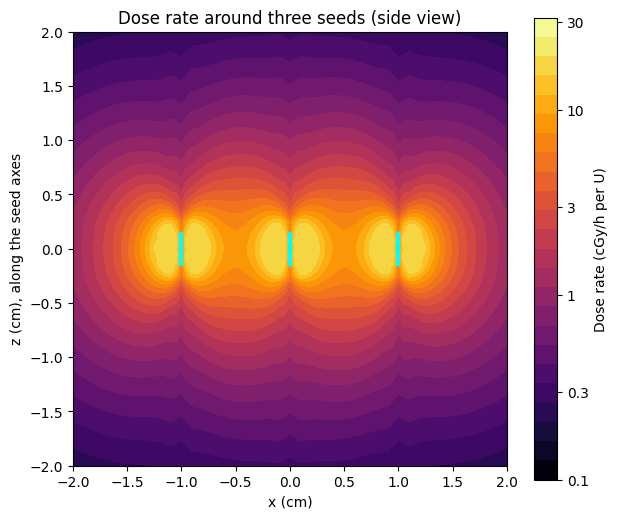

In [14]:
#dose map

from matplotlib.colors import LogNorm

# Three seeds in a row along x, all pointing along z
seeds = [(-1, 0, 0), (0, 0, 0), (1, 0, 0)]

# A grid of points from -2 to 2 cm in x and z (81 points each way)
x_values = np.linspace(-2, 2, 81)
z_values = np.linspace(-2, 2, 81)

# An empty 2D array to fill with dose rates: rows = z, columns = x
dose_map = np.zeros((len(z_values), len(x_values)))

#taking slices along the y axis

for i, z in enumerate(z_values):
    for j, x in enumerate(x_values):
        dose_map[i, j] = total_dose_rate((x,0,z), seeds, 1)   # total dose rate at the point (x, 0, z)
plt.figure(figsize=(7, 6))

plt.contourf(x_values, z_values, dose_map,
             levels=np.logspace(-1, 1.5, 25), norm=LogNorm(), cmap='inferno')
cbar = plt.colorbar(label='Dose rate (cGy/h per U)')
cbar.set_ticks([0.1, 0.3, 1, 3, 10, 30])
cbar.set_ticklabels(['0.1', '0.3', '1', '3', '10', '30'])



# Mark the seeds as short vertical lines (they point along z).
for seed in seeds:
    plt.plot([seed[0], seed[0]], [-0.14, 0.14], color='cyan', linewidth=3)

plt.xlabel('x (cm)')
plt.ylabel('z (cm), along the seed axes')
plt.title('Dose rate around three seeds (side view)')
plt.gca().set_aspect('equal')
plt.show()
